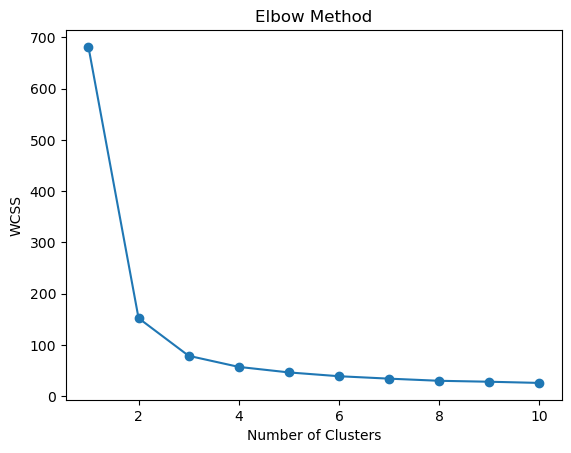

K-Means Clustering Results:
        species  Cluster
0        setosa        1
1        setosa        1
2        setosa        1
50   versicolor        0
51   versicolor        0
52   versicolor        2
53   versicolor        0
77   versicolor        2
100   virginica        2

Number of data points in each cluster:
Cluster
0    62
1    50
2    38
Name: count, dtype: int64


In [1]:
'''Clustering Analysis (Any one) 
A. Implement K-Means clustering on Iris.csv dataset. Determine the number of clusters 
using the elbow method. 
Dataset Link: https://www.kaggle.com/datasets/uciml/iris '''
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Load Iris dataset using URL
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
data = pd.read_csv(url)

# Select numerical features
X = data.drop('species', axis=1)

# Find optimal clusters using Elbow Method
wcss = []

for i in range(1, 11):
    model = KMeans(n_clusters=i, random_state=42, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

# Plot Elbow Graph
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

# Apply K-Means Clustering with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data['Cluster'] = kmeans.fit_predict(X)

# Display clustering results
print("K-Means Clustering Results:")
print(data.groupby('Cluster').head(3)[['species', 'Cluster']])

# Display cluster counts
print("\nNumber of data points in each cluster:")
print(data['Cluster'].value_counts().sort_index())